In [2]:
#Importing libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import ast
from datasets import load_dataset

#Loading the data
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

#Cleaning the date and skills columns
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

c:\Users\amire\anaconda3\envs\python_course\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
# Defining countries that we will filter with
mena_countries = ['Sudan','Egypt', 'Kuwait', 'Saudi Arabia', 'Jordan', 'United Arab Emirates', 'Lebanon', 'Libya', 'Syria', 'Qatar', 'Iraq',
                   'Morocco', 'Palestine', 'Algeria', 'Tunisia', 'Bahrain', 'Oman', 'Yemen'  ]

# Defining job roles
job_roles = ['Data Analyst', 'Data Engineer', 'Data Scientist']

# Filtering data frame to have only the top three data roles in mena region countries
df_mena = df[(df['job_country'].isin(mena_countries)) & (df['job_title_short'].isin(job_roles)) ]

# Percentages of Data Analyst skills were not as expected, SQL was expected to score around 60%
# Potential cause: job_skills column for data analyst roles has NA values
da = df_mena[df_mena['job_title_short'] == 'Data Analyst']
print(len(da))                         
print(da['job_skills'].notna().sum())
# As the output reveals the job_skills column has 2326 NA values for data analyst role 
# Fix: Adding notna to initial filtering of the original df

df_mena = df[(df['job_country'].isin(mena_countries)) & (df['job_title_short'].isin(job_roles)) & (df['job_skills'].notna())]

df_mena['job_country'].unique()
# There are no job postings from Syria

7489
5163


<ArrowStringArray>
[               'Sudan', 'United Arab Emirates',              'Tunisia',
              'Lebanon',               'Kuwait',                'Egypt',
         'Saudi Arabia',              'Morocco',                 'Iraq',
               'Jordan',                'Qatar',                 'Oman',
              'Bahrain',                'Yemen',            'Palestine',
              'Algeria',                'Libya']
Length: 17, dtype: str

In [4]:
df_job_skills = df_mena.explode('job_skills')
df_job_skills_count = df_job_skills.groupby(['job_skills', 'job_title_short']).size()


In [5]:
df_job_skills_count = df_job_skills_count.reset_index(name= 'skill_count')


In [6]:
top_skills = df_job_skills_count.sort_values(by= ['job_title_short','skill_count'], ascending=[True,False]).groupby('job_title_short').head(5)

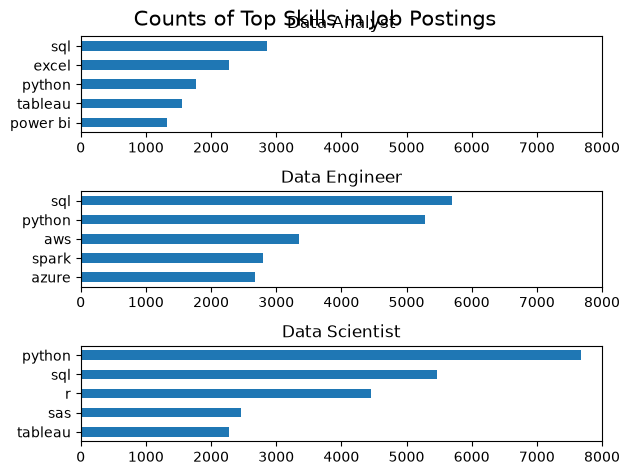

In [7]:
fig,ax = plt.subplots(3,1)
for i,roles in enumerate(job_roles):
    df_plot = top_skills[top_skills['job_title_short'] == roles]
    df_plot.plot(kind = 'barh', x= 'job_skills', y= 'skill_count', ax = ax[i], title = roles)
    ax[i].invert_yaxis()
    ax[i].set_ylabel('')
    ax[i].set_xlim(0,8000)
    ax[i].legend().set_visible(False)
fig.tight_layout(h_pad= 1)
fig.suptitle('Counts of Top Skills in Job Postings', fontsize = 15)
plt.show()

In [8]:
# Adding percentage column to have a clearer picture of what's the likelihood of a role to appear in a job posting
df_job_title_count = df_mena['job_title_short'].value_counts().reset_index(name= 'jobs_total')
df_skill_perc = pd.merge(top_skills, df_job_title_count, how = 'left', on = 'job_title_short')

In [9]:
df_skill_perc['skill_percentage'] = df_skill_perc['skill_count'] / df_skill_perc['jobs_total'] * 100

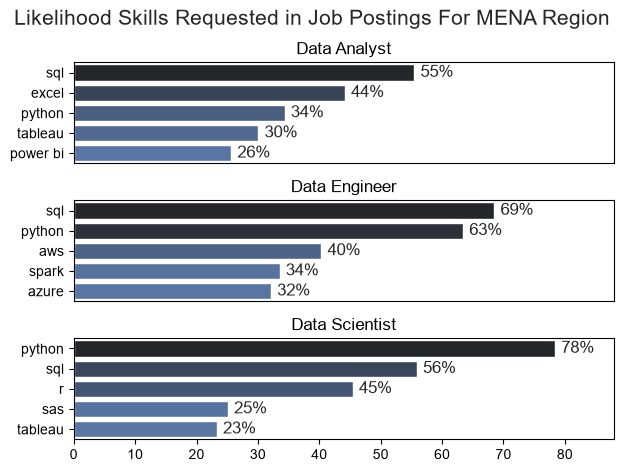

In [10]:
fig,ax = plt.subplots(3,1)

sns.set_theme(style = 'ticks')

for i,roles in enumerate(job_roles):
    df_plot = df_skill_perc[df_skill_perc['job_title_short'] == roles]
    sns.barplot(data = df_plot, y= 'job_skills', x= 'skill_percentage', ax = ax[i], hue = 'skill_count', palette = 'dark:b_r')

    ax[i].set_ylabel('')
    ax[i].set_xlabel('')
    ax[i].legend().set_visible(False)
    ax[i].set_title(roles)
    ax[i].set_xlim(0,88)

    for n,v in enumerate(df_plot['skill_percentage']):
        ax[i].text(v+1, n , f'{v:.0f}%', va= 'center')
        
    if i != 2 :
        ax[i].set_xticks([])

fig.tight_layout(h_pad=1, rect=[0, 0, 1, 0.95])
fig.suptitle('Likelihood Skills Requested in Job Postings For MENA Region', fontsize = 15)
plt.show()